# Group Comparison — Plant Disease Recognition
**Course:** IT2011 AI & ML  |  **Dataset:** Plant Disease Recognition (Healthy / Powdery / Rust)

This notebook compares the best result from each member's model and discusses performance, expected behavior and challenges.
All numbers come from each member's own notebook output (test set = 150 images).



## 1. Results tables

In [1]:
import pandas as pd

# ---- EDIT HERE if any member's best result changes ----
table_a = pd.DataFrame([
    ['SVM',           'V5 grid search (C=100, gamma=1)', 'colour histogram', 0.813, 0.813, 'CV'],
    ['Random Forest', 'V4, 50 trees',                    'colour histogram', 0.900, 0.900, 'CV'],
    ['CNN scratch',   'V4 baseline, no augmentation',    'images 128x128',   0.947, 0.947, 'validation'],
    ['MobileNetV2',   'v2 frozen, no augmentation',      'images 224x224',   0.987, 0.987, 'test'],
], columns=['Model', 'Best variety', 'Features', 'Test acc', 'Test macro-F1', 'Selected by'])

table_b = pd.DataFrame([
    ['PCA',     '150 components',  '80.7% variance retained; downstream SVM test acc 0.707, macro-F1 0.706'],
    ['K-Means', 'pixels+PCA, k=3', 'ARI 0.210 and NMI 0.204 (train); ARI 0.099 (test)'],
], columns=['Model', 'Best variety', 'Result'])

print('Table A: supervised models (150 test images)')
display(table_a)
print('Table B: PCA and K-Means (accuracy does not apply, different metrics)')
display(table_b)

Table A: supervised models (150 test images)


,Model,Best variety,Features,Test acc,Test macro-F1,Selected by
0,SVM,"V5 grid search (C=100, gamma=1)",colour histogram,0.813,0.813,CV
1,Random Forest,"V4, 50 trees",colour histogram,0.900,0.900,CV
2,CNN scratch,"V4 baseline, no augmentation",images 128x128,0.947,0.947,validation
3,MobileNetV2,"v2 frozen, no augmentation",images 224x224,0.987,0.987,test


Table B: PCA and K-Means (accuracy does not apply, different metrics)


,Model,Best variety,Result
0,PCA,150 components,80.7% variance retained; downstream SVM test a...
1,K-Means,"pixels+PCA, k=3",ARI 0.210 and NMI 0.204 (train); ARI 0.099 (test)


**Why two tables?** PCA does not predict labels and K-Means is unsupervised, so test accuracy and F1 do not apply to them.
They are judged by variance retained / downstream accuracy (PCA) and Adjusted Rand Index (K-Means).

## 2. Chart: best variety of each supervised model

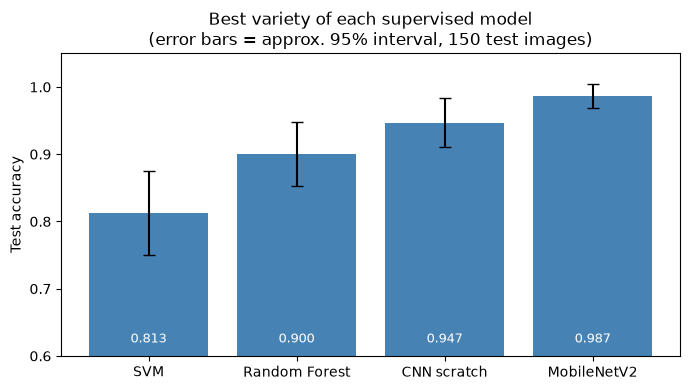

In [2]:
import numpy as np, matplotlib.pyplot as plt, os
os.makedirs('../results/eda_visualizations', exist_ok=True)

n = 150                                                    # number of test images
err = 1.96 * np.sqrt(table_a['Test acc'] * (1 - table_a['Test acc']) / n)   # approx. 95% interval

plt.figure(figsize=(7, 4))
plt.bar(table_a['Model'], table_a['Test acc'], yerr=err, capsize=4, color='steelblue')
for i, v in enumerate(table_a['Test acc']):
    plt.text(i, 0.62, f'{v:.3f}', ha='center', color='white', fontsize=9)
plt.ylim(0.6, 1.05); plt.ylabel('Test accuracy')
plt.title('Best variety of each supervised model\n(error bars = approx. 95% interval, 150 test images)')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/group_comparison.png', dpi=200)
plt.show()

**How to read the error bars:** with only 150 test images, one image is 0.7%. The bars of the two CNN models overlap slightly,
so MobileNetV2's lead of 6 images is suggestive but not conclusive. The gap between the CNNs and SVM is larger than the bars.

## 3. Discussion

### Performance
The two CNN models performed best: MobileNetV2 reached 0.987 and the CNN from scratch reached 0.947 test accuracy.
Random Forest (0.900) and SVM (0.813) followed, and PCA + SVM was lowest at 0.707. K-Means clustering was weak (best ARI 0.210).
MobileNetV2 is ahead by 6 test images, but with only 150 test images and overlapping error bars this is suggestive, not conclusive.

### Features mattered more than the model
For SVM and Random Forest, colour-histogram features gave much better results than PCA on raw pixels
(Random Forest 0.900 vs 0.660, SVM 0.833 vs 0.673). This matches how the diseases look:
rust gives orange-brown spots and powdery mildew gives white patches.

### Expected behavior
- CNNs do well because they learn spatial patterns such as spots and texture, which flattened pixels and colour histograms do not capture.
- Colour histograms were the best features for the supervised models but the worst for K-Means. A likely reason is that without labels,
  K-Means groups images by overall colour or background and not by disease (not tested directly).
- PCA reduced the SVM fit time from about 263 s to under 3 s, at a cost of roughly 4 points of accuracy.
- A frozen ResNet-50 (about 24M parameters) reached only 0.887, below the much smaller frozen MobileNetV2 (about 2.4M parameters), so a bigger model was not better here.
- In the CNN from scratch, data augmentation behaved as expected: removing it (V4) pushed training accuracy to about 99.8% and widened the
  train-validation gap (0.048 vs 0.032 for V1), although test accuracy stayed at 0.947.

### Challenges
- The dataset is small (1,322 training, 60 validation and 150 test images), so small differences between models are unreliable.
  One test image is about 0.7%, and the three best CNN variants (V1, V2 and V4) all scored 0.947.
- Fully unfreezing MobileNetV2 dropped test accuracy to 0.807. Overfitting or disturbed pretrained features are likely causes, but we did not prove it.
- In the CNN from scratch, Dropout 0.5 alone did not hurt (test accuracy 0.947), but Dropout 0.5 combined with BatchNormalization dropped to 0.800
  with unstable validation accuracy. We did not test the exact cause.
- Members used different pipelines (MobileNetV2 at 224x224 on Colab; other models at 128x128 or cached features locally) and different
  selection rules (cross-validation, validation set, test set). MobileNetV2's variety (v2) was chosen using the test set, so its result is slightly optimistic. Its v1 variety (with augmentation) scored 0.967, only 3 images lower.
- Neural network training is random, so the CNN numbers can change slightly when a notebook is re-run.

### Conclusion
For this dataset, deep learning (especially transfer learning) gives the best accuracy, while colour-histogram features with Random Forest
are a strong and much cheaper classical alternative. Results should be confirmed with a larger test set or cross-validation before drawing firm conclusions.